# Phase 1 – Part A: Problem Understanding & Data Exploration
## Executive Clinical Screening & Triage Decision-Support Tool
**SWE485 – King Saud University – Group 3**

## 1. Introduction & Problem Statement

### 1.1 Domain
This project belongs to the **healthcare operations** domain. It focuses on early screening and triage for diabetes risk.

### 1.2 Problem Statement
Diabetes is one of the most common chronic diseases, and a large share of people with prediabetes or diabetes are unaware of their condition until complications appear. Healthcare organizations have limited clinical capacity, so they need an efficient way to decide **who should be prioritized for further clinical assessment**.

This project develops an **executive clinical screening and triage decision-support system** that classifies individuals into one of two screening categories based on health and lifestyle indicators:

- **0 – No Diabetes:** routine follow-up.
- **1 – Prediabetes or Diabetes:** recommended for further clinical assessment.

The system uses indicators such as BMI, high blood pressure, high cholesterol, physical activity, smoking, age group, and self-rated general health.

### 1.3 Type of Advice System
The system is a **medical screening and prioritization advice system** aimed at healthcare decision-makers. Its output is a recommendation on whether an individual should be referred for clinical assessment, together with (in Phase 2) a risk segment and an AI-generated preventive care summary.

### 1.4 Intended Users
- **Healthcare executives and managers:** to plan screening programs and allocate resources.
- **Healthcare professionals:** to prioritize individuals for clinical follow-up.

### 1.5 Scope and Limitations
- The system is a **screening and decision-support tool, not a medical diagnosis tool**. Final decisions remain with qualified clinicians.
- Because the goal is early screening, **missing an at-risk individual (false negative) is more costly than an extra referral (false positive)**. Recall on the positive class will therefore be a key evaluation priority in Part B.

## 2. Dataset Selection & Justification

### 2.1 Dataset Source
- **Name:** Diabetes Health Indicators Dataset
- **Source:** Kaggle – https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset
- **File used:** `diabetes_binary_5050split_health_indicators_BRFSS2015.csv`
- **Origin:** Derived from the CDC's **Behavioral Risk Factor Surveillance System (BRFSS) 2015**, an annual health-related telephone survey in the United States.

### 2.2 Dataset Goal
The dataset was prepared to study which health and lifestyle indicators are associated with diabetes, and to support building predictive models for diabetes risk. This matches our goal of classifying screening status.

### 2.3 Dataset Overview
| Property | Value |
|---|---|
| Records | 70,692 |
| Predictor features | 21 |
| Target variable | `Diabetes_binary` |
| Classes | 0 = No Diabetes, 1 = Prediabetes or Diabetes |
| Class balance | 50 / 50 |
| Data type | Structured / tabular |

### 2.4 Justification

**Relevance**
- The features (BMI, HighBP, HighChol, PhysActivity, Smoker, Age, GenHlth, and others) are well-known diabetes risk factors and are exactly the inputs a screening tool would rely on.
- The binary target directly represents our screening decision: refer for assessment or not.

**Completeness**
- Each record contains all 21 indicators, covering health conditions, lifestyle behaviors, healthcare access, and demographics.
- The dataset has no significant missing values, which reduces the need for imputation.

**Quality**
- It comes from a large, standardized public health survey (CDC BRFSS), not an ad-hoc collection.
- The balanced 50/50 version avoids the strong class imbalance of the original data, so models are not biased toward the majority class.

**Fit with project requirements**
- Size: 70,692 rows, well above the minimum of several hundred.
- Features: 21, above the 10–15 minimum.
- Structure: tabular, as required for Phase 1.
- Classes: 2, suitable for binary classification.
- Phase 2: after removing the target, the features can be used for clustering to create patient risk segments.

### 2.5 Known Limitations
- **Self-reported data:** survey answers may contain recall or reporting bias.
- **Coarse features:** blood pressure and cholesterol are binary (yes/no), and age is given in 13 groups rather than exact years.
- **Combined positive class:** prediabetes and diabetes are merged into one class.
- **Artificial balance:** the 50/50 split does not reflect real-world prevalence, so predicted probabilities should be interpreted with care.
- **Population:** the data represents U.S. adults in 2015 and may not generalize directly to other populations.

## 3. Initial Data Inspection

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Dataset/diabetes_binary_5050split_health_indicators_BRFSS2015.csv")
df.head()

In [55]:
import os

# Folder where the EDA figures are saved (next to this notebook)
os.makedirs("EDA_plots", exist_ok=True)

print("Shape (rows, columns):", df.shape)
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print()
df.info()

Shape (rows, columns): (70692, 22)

Duplicate rows: 1635

Total missing values: 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Diabetes_binary       70692 non-null  float64
 1   HighBP                70692 non-null  float64
 2   HighChol              70692 non-null  float64
 3   CholCheck             70692 non-null  float64
 4   BMI                   70692 non-null  float64
 5   Smoker                70692 non-null  float64
 6   Stroke                70692 non-null  float64
 7   HeartDiseaseorAttack  70692 non-null  float64
 8   PhysActivity          70692 non-null  float64
 9   Fruits                70692 non-null  float64
 10  Veggies               70692 non-null  float64
 11  HvyAlcoholConsump     70692 non-null  float64
 12  AnyHealthcare         70692 non-null  float64
 13  NoDocbcCost           70692 non-null  

**Observations:**
- The dataset contains 70,692 records and 22 columns (21 predictors + the target `Diabetes_binary`).
- There are no missing values.
- There are 1,635 duplicate rows (about 2.3% of the data). In survey data, two respondents can legitimately give identical answers, so duplicates are not necessarily errors. The decision to keep or remove them is left to the Preprocessing stage.
- All columns are stored as `float64`, even though most of them are binary (0/1) or ordinal categories (e.g., `Age`, `GenHlth`, `Education`, `Income`). Only `BMI`, `MentHlth`, and `PhysHlth` are truly numeric.

## 4. Exploratory Data Analysis (EDA)

### 4.1 Class Distribution

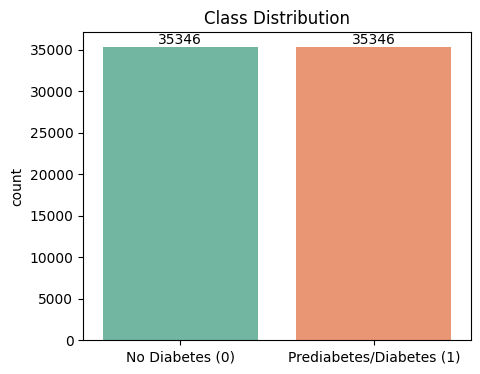

In [56]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Diabetes_binary", hue="Diabetes_binary", data=df,
                   palette="Set2", legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["No Diabetes (0)", "Prediabetes/Diabetes (1)"])
ax.set_title("Class Distribution")
ax.set_xlabel("")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.savefig("EDA_plots/01_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**What it shows:** The number of records in each class of the target variable.

**Observation:** The classes in our dataset are perfectly balanced, with 35,346 records in each class.

**Why it matters:** If one class were much larger than the other, a model could become "lazy" and simply predict the majority class every time. It would look accurate, but it would not really learn anything and would not be useful for us. Since our classes are balanced, we avoid this problem.

**Limitation:** This balance comes from a pre-processed version of the original BRFSS data (the full dataset is heavily imbalanced). Real-world prevalence of diabetes is much lower than 50%, so model performance on this version may not reflect performance on a real population.

### 4.2 BMI Distribution

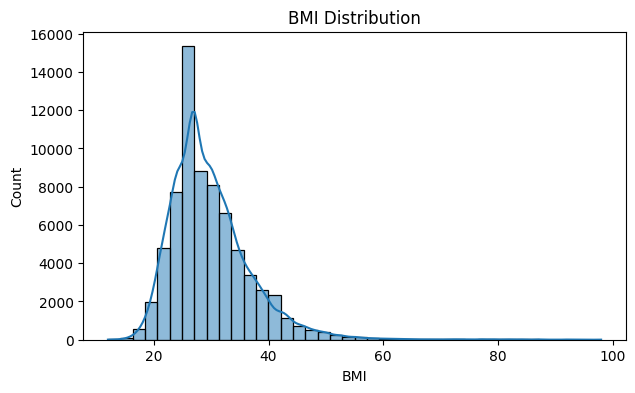

count    70692.000000
mean        29.856985
std          7.113954
min         12.000000
25%         25.000000
50%         29.000000
75%         33.000000
max         98.000000
Name: BMI, dtype: float64

In [57]:
plt.figure(figsize=(7, 4))
sns.histplot(df["BMI"], bins=40, kde=True)
plt.title("BMI Distribution")
plt.savefig("EDA_plots/02_bmi_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

df["BMI"].describe()

**What it shows:** The distribution of Body Mass Index (BMI) across all respondents.

**Observation:** Most respondents have a BMI around 26-27, where the histogram peaks (about 15,000 records). After the peak, the counts drop noticeably and a long, thin tail stretches to the right toward very high values. The values close to 98 are very unlikely to be realistic and are most likely recording errors.

**Why it matters:** These extreme values can affect scaling and some models, so Preprocessing should decide whether to cap or remove them.

### 4.3 BMI by Diabetes Status

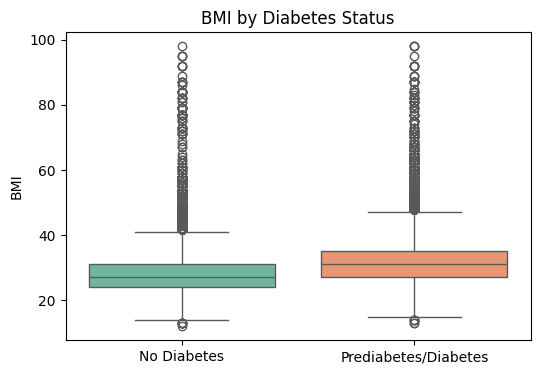

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,,,,,,,,
0.0,35346.0,27.769960,6.187636,12.0,24.0,27.0,31.0,98.0
1.0,35346.0,31.944011,7.363401,13.0,27.0,31.0,35.0,98.0


In [58]:
plt.figure(figsize=(6, 4))
sns.boxplot(x="Diabetes_binary", y="BMI", hue="Diabetes_binary", data=df,
            palette="Set2", legend=False)
plt.xticks([0, 1], ["No Diabetes", "Prediabetes/Diabetes"])
plt.xlabel("")
plt.title("BMI by Diabetes Status")
plt.savefig("EDA_plots/03_bmi_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

df.groupby("Diabetes_binary")["BMI"].describe()

**What it shows:** The distribution of BMI for each class, using box plots.

**Observation:** The box for the diabetes group sits higher than the box for the no-diabetes group (median about 31 vs. 27). However, the two boxes overlap, so BMI alone does not clearly separate the groups. Both groups also have many high outliers (the circles above the whiskers), reaching up to 98.

**Why it matters:** BMI is useful but not enough on its own, so our models will need to combine it with other features.

### 4.4 Diabetes Rate by Age Category

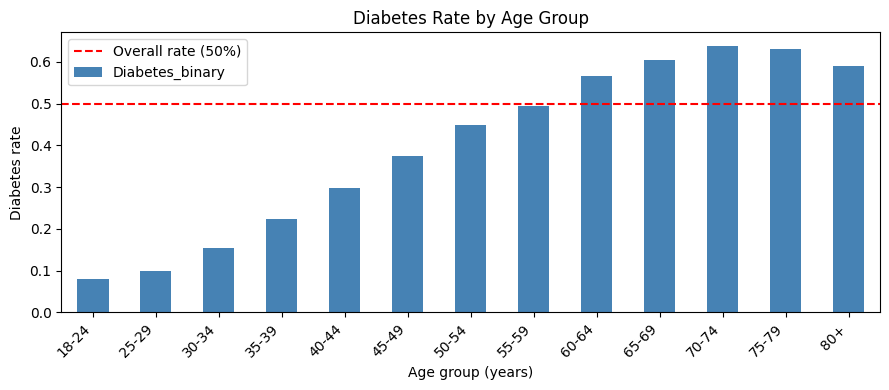

Age
1.0     0.079673
2.0     0.100287
3.0     0.153245
4.0     0.224132
5.0     0.298580
6.0     0.374785
7.0     0.449360
8.0     0.495525
9.0     0.566950
10.0    0.604090
11.0    0.639110
12.0    0.630886
13.0    0.591412
Name: Diabetes_binary, dtype: float64

In [59]:
age_labels = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
              "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]

plt.figure(figsize=(9, 4))
age_rate = df.groupby("Age")["Diabetes_binary"].mean()
ax = age_rate.plot(kind="bar", color="steelblue")
ax.set_xticklabels(age_labels, rotation=45, ha="right")
plt.ylabel("Diabetes rate")
plt.xlabel("Age group (years)")
plt.title("Diabetes Rate by Age Group")
plt.axhline(0.5, color="red", linestyle="--", label="Overall rate (50%)")
plt.legend()
plt.tight_layout()
plt.savefig("EDA_plots/04_age_vs_diabetes.png", dpi=150, bbox_inches="tight")
plt.show()

age_rate

**What it shows:** The share of respondents with prediabetes/diabetes within each age group. The red dashed line marks the overall rate of 50%.

**Observation:** The diabetes rate increases with age, from about 8% in the youngest group to about 64% at ages 70-74. In the last two groups (75-79 and 80+), the rate starts to decrease slightly.

**Why it matters:** Age is a strong signal for risk prioritization. The slight drop in the oldest groups cannot be explained from our data. Possible reasons include survivorship effects or smaller sample sizes, but we do not draw conclusions about the cause. Also, the exact percentages reflect our balanced sample, not real population rates.

### 4.5 Diabetes Rate by Binary Risk Factors

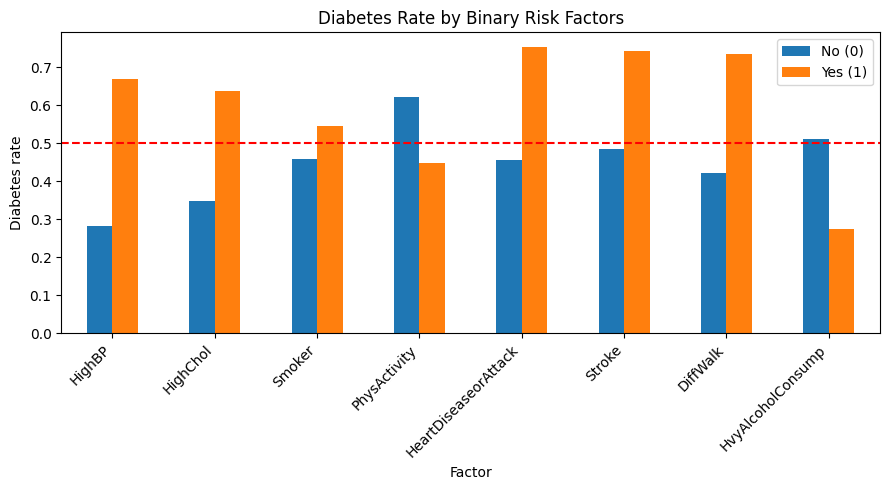

,No (0),Yes (1)
Factor,,
HighBP,0.283,0.668
HighChol,0.348,0.637
Smoker,0.459,0.545
PhysActivity,0.622,0.448
HeartDiseaseorAttack,0.456,0.754
Stroke,0.484,0.744
DiffWalk,0.421,0.734
HvyAlcoholConsump,0.510,0.275


In [60]:
risk = ["HighBP", "HighChol", "Smoker", "PhysActivity",
        "HeartDiseaseorAttack", "Stroke", "DiffWalk", "HvyAlcoholConsump"]

rows = []
for c in risk:
    g = df.groupby(c)["Diabetes_binary"].mean()
    rows.append({"Factor": c, "No (0)": g[0.0], "Yes (1)": g[1.0]})
rate_df = pd.DataFrame(rows).set_index("Factor")

rate_df.plot(kind="bar", figsize=(9, 5))
plt.ylabel("Diabetes rate")
plt.title("Diabetes Rate by Binary Risk Factors")
plt.axhline(0.5, color="red", linestyle="--")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("EDA_plots/05_risk_factors.png", dpi=150, bbox_inches="tight")
plt.show()

rate_df.round(3)

**What it shows:** The diabetes rate for respondents without (No) and with (Yes) each binary factor.

**Observation:** HighBP shows the biggest difference: the diabetes rate is about 28% without high blood pressure and 67% with it. It is followed by DiffWalk, heart disease, and high cholesterol. Physical activity shows the expected direction: active people have a lower diabetes rate (45% vs. 62%). Smoking shows the weakest difference. Heavy alcohol consumption shows an unexpected direction, but this group is small (about 4% of the data), so we do not interpret it.

**Why it matters:** These factors can help prioritize who should be screened first. The plot shows association, not causation.

### 4.6 Diabetes Rate by General Health

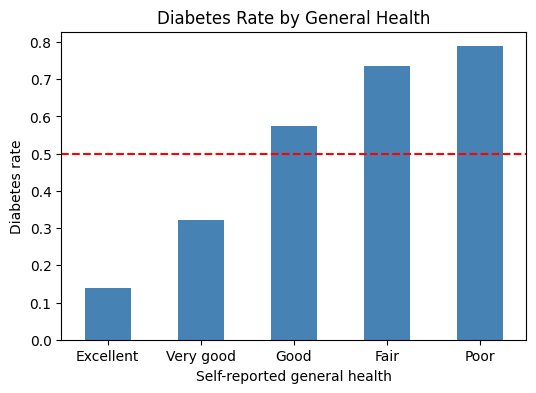

GenHlth
Excellent    0.138
Very good    0.321
Good         0.574
Fair         0.736
Poor         0.788
Name: Diabetes_binary, dtype: float64

In [61]:
gh_labels = {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"}
gh_rate = df.groupby("GenHlth")["Diabetes_binary"].mean()
gh_rate.index = gh_rate.index.map(gh_labels)

plt.figure(figsize=(6, 4))
gh_rate.plot(kind="bar", color="steelblue")
plt.ylabel("Diabetes rate")
plt.xlabel("Self-reported general health")
plt.title("Diabetes Rate by General Health")
plt.axhline(0.5, color="red", linestyle="--")
plt.xticks(rotation=0)
plt.savefig("EDA_plots/06_genhlth_vs_diabetes.png", dpi=150, bbox_inches="tight")
plt.show()

gh_rate.round(3)

**What it shows:** The diabetes rate for each level of self-reported general health (1 = Excellent to 5 = Poor).

**Observation:** The diabetes rate increases as self-reported health gets worse, from about 14% among people who rate their health as excellent to about 79% among those who rate it as poor.

**Why it matters:** General health is a simple indicator that is strongly related to diabetes and could be useful in our screening system. Since it is self-reported, it may partly reflect people who already have diabetes or other conditions rating their health lower, so we do not treat it as a cause.

### 4.7 Correlation Heatmap

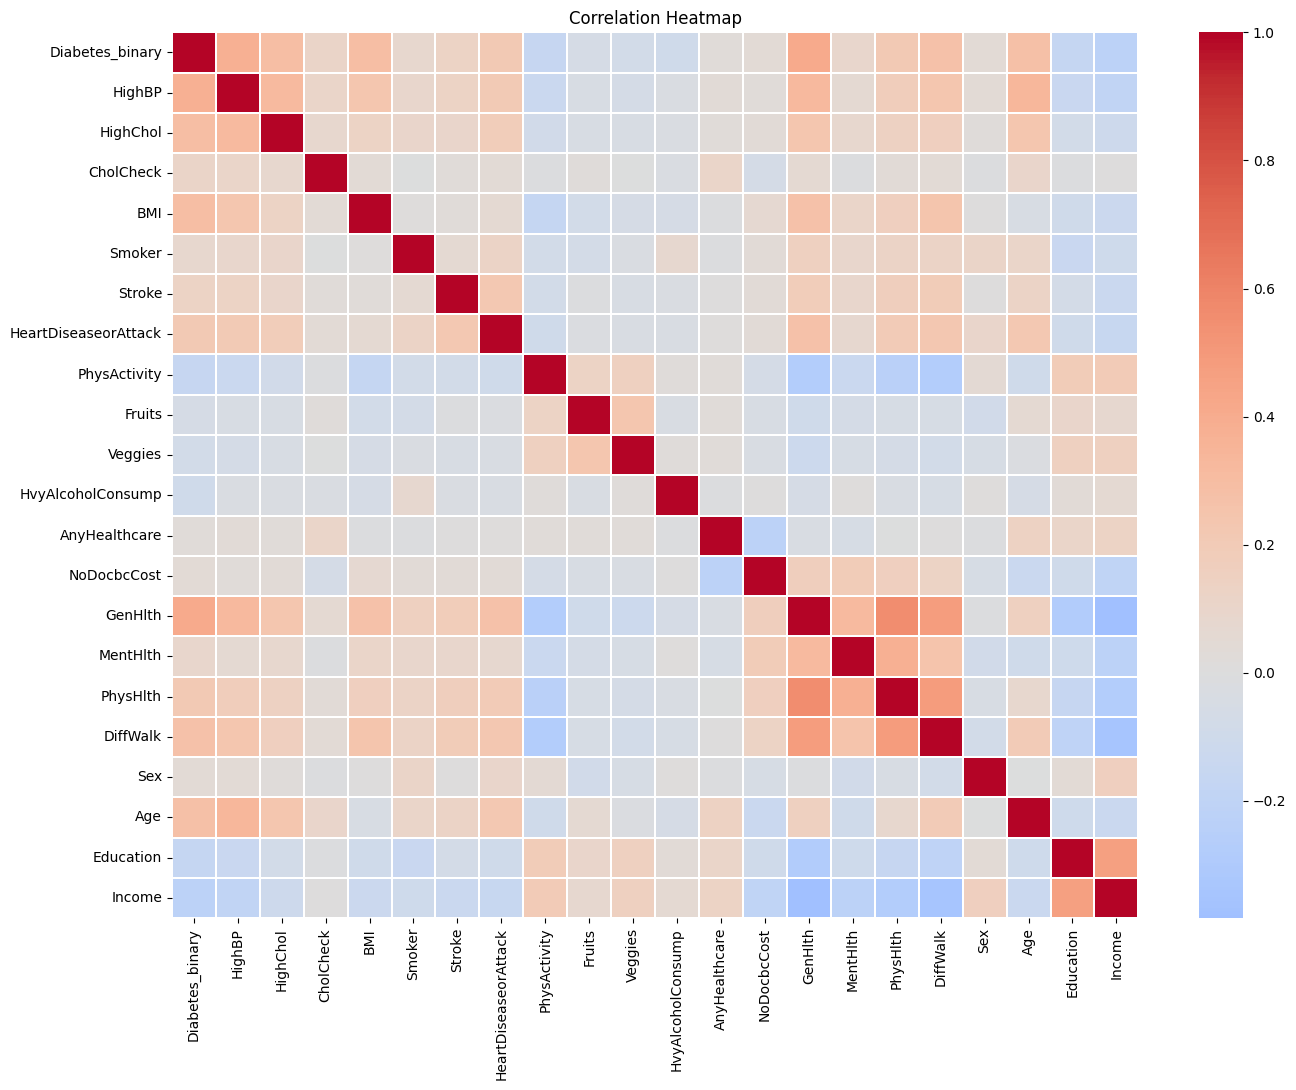

In [62]:
plt.figure(figsize=(14, 11))
sns.heatmap(df.corr(), cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("EDA_plots/07_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**What it shows:** Pairwise correlations between all variables. Red indicates positive correlation, blue indicates negative correlation.

**Observation:** Looking at the first row (the relationship with Diabetes_binary), HighBP and BMI show a positive relationship with diabetes, meaning diabetes is more common when they are high. PhysActivity and Education show a negative relationship, meaning diabetes is less common when they are higher. The strongest positive relationships are with GenHlth and HighBP, and the strongest negative one is with Income.

**Why it matters:** This gives us a first idea of which features may be useful for prediction. None of the relationships is very strong, so our models will need to combine several features. These are correlations, not proof of cause.

### 4.8 Correlation of Each Feature with Diabetes

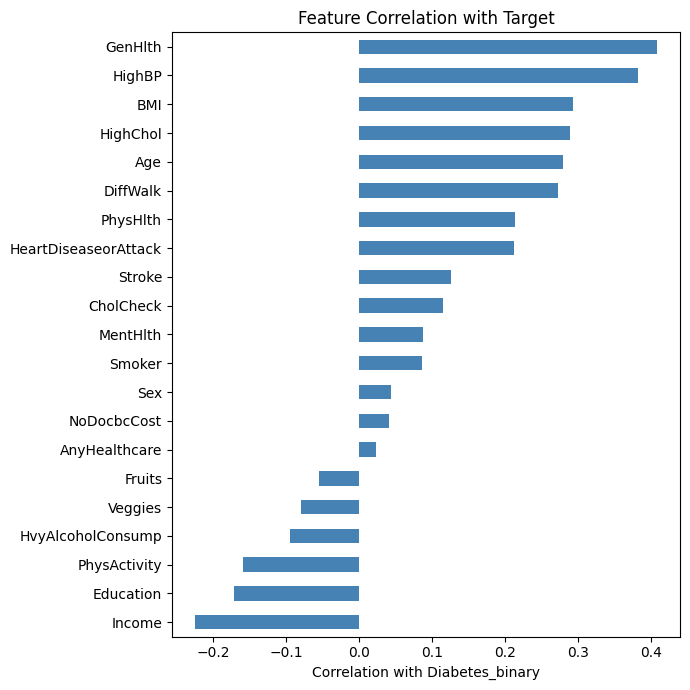

GenHlth                 0.408
HighBP                  0.382
BMI                     0.293
HighChol                0.289
Age                     0.279
DiffWalk                0.273
PhysHlth                0.213
HeartDiseaseorAttack    0.212
Stroke                  0.125
CholCheck               0.115
MentHlth                0.087
Smoker                  0.086
Sex                     0.044
NoDocbcCost             0.041
AnyHealthcare           0.023
Fruits                 -0.054
Veggies                -0.079
HvyAlcoholConsump      -0.095
PhysActivity           -0.159
Education              -0.170
Income                 -0.224
Name: Diabetes_binary, dtype: float64

In [63]:
corr_target = (df.corr()["Diabetes_binary"]
               .drop("Diabetes_binary")
               .sort_values())

plt.figure(figsize=(7, 7))
corr_target.plot(kind="barh", color="steelblue")
plt.xlabel("Correlation with Diabetes_binary")
plt.title("Feature Correlation with Target")
plt.tight_layout()
plt.savefig("EDA_plots/08_target_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

corr_target.round(3).sort_values(ascending=False)

**What it shows:** The correlation of each feature with `Diabetes_binary`, sorted from strongest positive to strongest negative.

**Observation:** GenHlth has the strongest correlation with diabetes (0.41), followed by HighBP (0.38). BMI, HighChol, Age, and DiffWalk are around 0.27-0.29. Income (-0.22), Education (-0.17), and PhysActivity (-0.16) have negative correlations.

**Why it matters:** Even the strongest value (0.41) is well below 1, so no single feature is enough to predict diabetes. Our models will need to combine several features. Correlation does not mean cause.

### 4.9 Summary Statistics

In [64]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,70692.0,0.50,0.50,0.0,0.0,0.5,1.0,1.0
HighBP,70692.0,0.56,0.50,0.0,0.0,1.0,1.0,1.0
HighChol,70692.0,0.53,0.50,0.0,0.0,1.0,1.0,1.0
CholCheck,70692.0,0.98,0.16,0.0,1.0,1.0,1.0,1.0
BMI,70692.0,29.86,7.11,12.0,25.0,29.0,33.0,98.0
Smoker,70692.0,0.48,0.50,0.0,0.0,0.0,1.0,1.0
Stroke,70692.0,0.06,0.24,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,70692.0,0.15,0.35,0.0,0.0,0.0,0.0,1.0
PhysActivity,70692.0,0.70,0.46,0.0,0.0,1.0,1.0,1.0
Fruits,70692.0,0.61,0.49,0.0,0.0,1.0,1.0,1.0


**Observation:** Most of the variables are binary (0/1), so their mean shows the percentage of people with a value of 1. For example, 56% of respondents have high blood pressure. CholCheck (98%) and AnyHealthcare (95%) are almost the same for everyone. MentHlth and PhysHlth are mostly 0 (the median is 0), but some people have up to 30 unhealthy days. BMI reaches 98, which matches the outliers we saw earlier.

**Why it matters:** Features that are almost the same for everyone, like CholCheck and AnyHealthcare, are unlikely to help the models tell the classes apart. The features also have very different scales, so we will need to consider scaling in Preprocessing.

## 5. Preprocessing Pipeline

_To be completed by the preprocessing team members._

## 6. Preprocessed Dataset Ready for Modeling

_To be completed._

## 7. Key Insights & Challenges

### 7.1 EDA Insights

1. The classes are perfectly balanced, with 35,346 records in each class.
2. There are 1,635 duplicate rows. Preprocessing needs to decide whether to keep or remove them.
3. Most respondents have a BMI around 26-27 (the peak of the histogram, about 15,000 records).
4. BMI values close to 98 are most likely recording errors. Preprocessing needs to decide whether to cap or remove them.
5. HighBP and BMI have a positive relationship with diabetes, meaning diabetes is more common when they are high. PhysActivity and Education have a negative relationship, meaning diabetes is less common when they are higher.
6. The diabetes rate increases with age until the 70-74 age group, then decreases slightly in the oldest groups.
7. GenHlth is the strongest feature (0.41), but it is not enough on its own because the value is far from 1. Our models will need to combine several features.

### 7.2 Preprocessing Insights & Challenges

_To be completed by the preprocessing team members._